In [1]:
import torch
import matplotlib.pyplot as plt
import torchvision

from models import NeuralNetworkClassificationModel

from learners import ClassificationLearner

from utilities import plot_images_and_labels, plot_training_process


device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
print('device:', device)

device: cpu


In [2]:
random_seed = 1

batch_size_train = 64
batch_size_test = 1000
epochs = 5
learning_rates = [0.01, 0.1, 0.25]

transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor()
])

train_dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_dataset = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)

print("train data shape:", tuple(train_dataset.data.shape))
print("train targets shape:", tuple(train_dataset.targets.shape))
print("test data shape:", tuple(test_dataset.data.shape))
print("test targets shape:", tuple(test_dataset.targets.shape))
print()

train data shape: (60000, 28, 28)
train targets shape: (60000,)
test data shape: (10000, 28, 28)
test targets shape: (10000,)



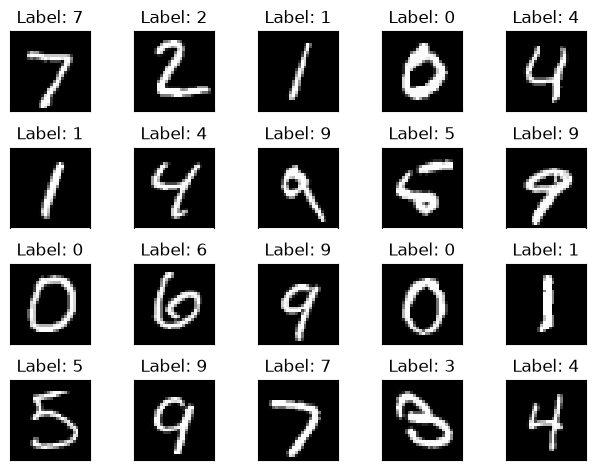

In [3]:
train_subset, valid_subset = torch.utils.data.random_split(train_dataset, [0.8, 0.2])

# create dataloaders that sample batches from the training, validation and test datasets
train_dataloader = torch.utils.data.DataLoader(dataset=train_subset, batch_size=batch_size_train, shuffle=True)
valid_dataloader = torch.utils.data.DataLoader(dataset=valid_subset, batch_size=batch_size_test, shuffle=False)
test_dataloader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size_test, shuffle=False)

# plot a sample of images and labels
sample_data, sample_targets = next(iter(test_dataloader))
plot_images_and_labels(sample_data, sample_targets)

In [4]:
results = {}
for lr in learning_rates:
    print(f"--- lr={lr} ---")

    torch.manual_seed(random_seed)
    torch.cuda.manual_seed(random_seed)

    model = NeuralNetworkClassificationModel()
    criterion = torch.nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(),lr)

    learner = ClassificationLearner(model, criterion, optimizer)
    train_losses, valid_losses, valid_accuracies = learner.train(train_dataloader, valid_dataloader, epochs, device)

    min_valid_loss = min(valid_losses)
    min_valid_loss_index = valid_losses.index(min_valid_loss)
    min_valid_accuracy = valid_accuracies[min_valid_loss_index]

    learner.load("leader")

    test_loss, test_accuracy = learner.test(test_dataloader, device)

    results[lr] = {
        "train_losses": train_losses,
        "valid_losses": valid_losses,
        "valid_accuracies": valid_accuracies,
        "min_valid_loss": min_valid_loss,
        "valid_accuracy": min_valid_accuracy,
    }

    print(f"lr={lr}: valid loss = {min_valid_loss:.4f}, valid accuracy = {100 * min_valid_accuracy:.2f}%")
    print()


--- lr=0.01 ---
train epoch [1/5]:	train loss = 1.8837	valid loss = 1.0731	valid accuracy = 76.64%
train epoch [2/5]:	train loss = 0.6893	valid loss = 0.5205	valid accuracy = 85.91%
train epoch [3/5]:	train loss = 0.4469	valid loss = 0.4199	valid accuracy = 88.17%
train epoch [4/5]:	train loss = 0.3800	valid loss = 0.3762	valid accuracy = 89.33%
train epoch [5/5]:	train loss = 0.3438	valid loss = 0.3509	valid accuracy = 90.05%

lr=0.01: valid loss = 0.3509, valid accuracy = 90.05%

--- lr=0.1 ---
train epoch [1/5]:	train loss = 0.5533	valid loss = 0.2864	valid accuracy = 91.82%
train epoch [2/5]:	train loss = 0.2123	valid loss = 0.1926	valid accuracy = 94.31%
train epoch [3/5]:	train loss = 0.1439	valid loss = 0.1520	valid accuracy = 95.39%
train epoch [4/5]:	train loss = 0.1092	valid loss = 0.1288	valid accuracy = 96.31%
train epoch [5/5]:	train loss = 0.0877	valid loss = 0.1190	valid accuracy = 96.47%

lr=0.1: valid loss = 0.1190, valid accuracy = 96.47%

--- lr=0.25 ---
train epoch 

In [5]:
print(f"{'lr':>8} | {'valid loss':>10} | {'valid acc':>9}")
print("-" * 34)
for lr, r in results.items():
    print(f"{lr:>8} | {r['min_valid_loss']:>10.4f} | {100 * r['valid_accuracy']:>8.2f}%")

best_lr = min(results, key=lambda lr: results[lr]["min_valid_loss"])
print(f"\nBest learning rate: {best_lr}")

      lr | valid loss | valid acc
----------------------------------
    0.01 |     0.3509 |    90.05%
     0.1 |     0.1190 |    96.47%
    0.25 |     0.0972 |    97.18%

Best learning rate: 0.25


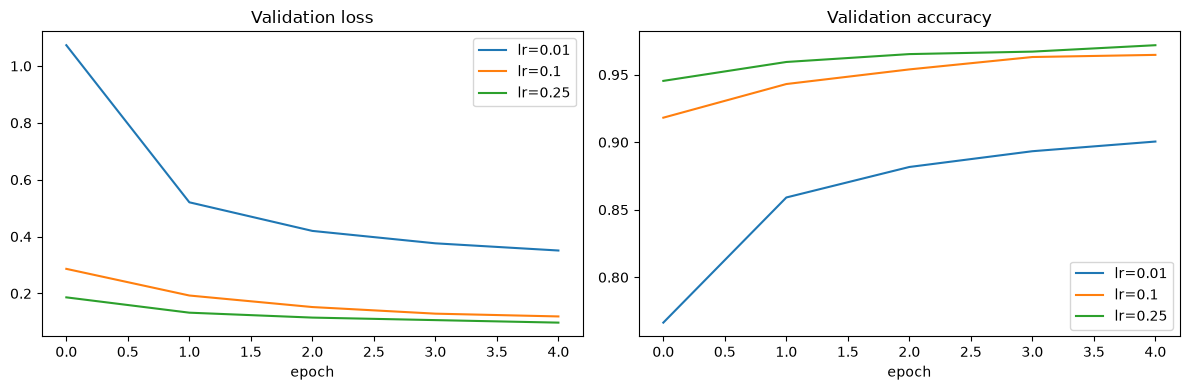

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for lr, r in results.items():
    axes[0].plot(r["valid_losses"], label=f"lr={lr}")
    axes[1].plot(r["valid_accuracies"], label=f"lr={lr}")

axes[0].set_title("Validation loss")
axes[0].set_xlabel("epoch")
axes[0].legend()

axes[1].set_title("Validation accuracy")
axes[1].set_xlabel("epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

train epoch [1/50]:	train loss = 0.3847	valid loss = 0.1861	valid accuracy = 94.54%
train epoch [2/50]:	train loss = 0.1309	valid loss = 0.1322	valid accuracy = 95.94%
train epoch [3/50]:	train loss = 0.0896	valid loss = 0.1149	valid accuracy = 96.53%
train epoch [4/50]:	train loss = 0.0693	valid loss = 0.1061	valid accuracy = 96.71%
train epoch [5/50]:	train loss = 0.0535	valid loss = 0.0972	valid accuracy = 97.18%
train epoch [6/50]:	train loss = 0.0422	valid loss = 0.1097	valid accuracy = 96.89%
train epoch [7/50]:	train loss = 0.0340	valid loss = 0.0993	valid accuracy = 97.14%
train epoch [8/50]:	train loss = 0.0278	valid loss = 0.0933	valid accuracy = 97.34%
train epoch [9/50]:	train loss = 0.0217	valid loss = 0.0955	valid accuracy = 97.37%
train epoch [10/50]:	train loss = 0.0186	valid loss = 0.1073	valid accuracy = 97.04%
train epoch [11/50]:	train loss = 0.0153	valid loss = 0.1116	valid accuracy = 97.20%
train epoch [12/50]:	train loss = 0.0127	valid loss = 0.1082	valid accurac

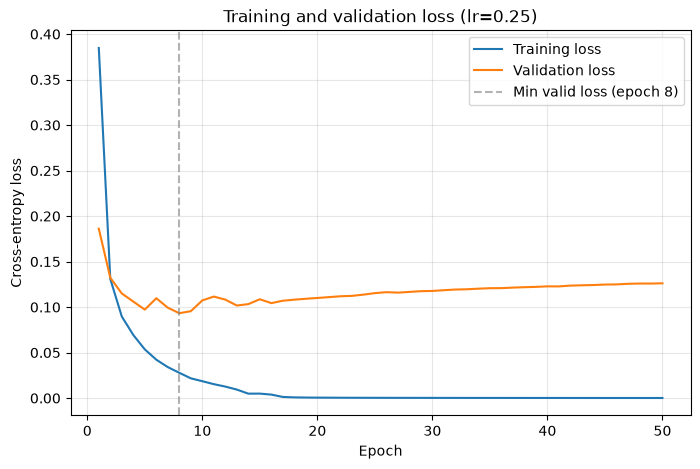

In [8]:
epochs = 50

torch.manual_seed(random_seed)
torch.cuda.manual_seed(random_seed)

model = NeuralNetworkClassificationModel()
criterion = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), best_lr)

learner = ClassificationLearner(model, criterion, optimizer)
train_losses, valid_losses, valid_accuracies = learner.train(
    train_dataloader, valid_dataloader, epochs, device
)

plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, label="Training loss")
plt.plot(range(1, epochs + 1), valid_losses, label="Validation loss")

best_epoch = valid_losses.index(min(valid_losses)) + 1
plt.axvline(best_epoch, color="gray", linestyle="--", alpha=0.6,
            label=f"Min valid loss (epoch {best_epoch})")

plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title(f"Training and validation loss (lr={best_lr})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

First reached 97.35% validation accuracy at epoch 9
  train loss: 0.0217
  valid loss: 0.0955
  valid acc:  97.37%


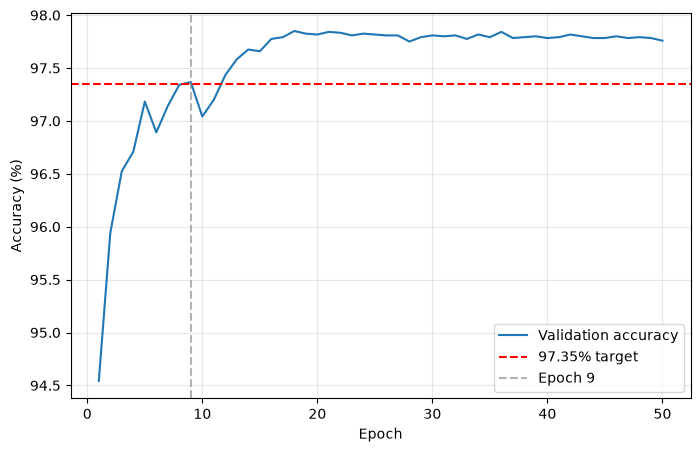

In [9]:
target = 0.9735

reached = next((i + 1 for i, a in enumerate(valid_accuracies) if a >= target), None)

if reached is None:
    print(f"Target of {100*target:.2f}% was never reached "
          f"(max = {100*max(valid_accuracies):.2f}%).")
else:
    i = reached - 1
    print(f"First reached {100*target:.2f}% validation accuracy at epoch {reached}")
    print(f"  train loss: {train_losses[i]:.4f}")
    print(f"  valid loss: {valid_losses[i]:.4f}")
    print(f"  valid acc:  {100*valid_accuracies[i]:.2f}%")

# accuracy plot
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), [100 * a for a in valid_accuracies], label="Validation accuracy")
plt.axhline(100 * target, color="red", linestyle="--", label="97.35% target")
if reached:
    plt.axvline(reached, color="gray", linestyle="--", alpha=0.6, label=f"Epoch {reached}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()